# Reading a coding ban inside Qwen3-8B

**Demo notebook for experiment 12 (round 2): what does a model do, internally, when the prompt bans the algorithm it would normally write?**

Asked for a path-search function, Qwen3-8B almost always writes the textbook algorithm. This experiment bans that default in the prompt and reads the model's internals while it writes code:

| Task | Prompt | Banned algorithm X | Main substitute X' |
|---|---|---|---|
| T1 | grid path, `solve(grid, start, goal)` | breadth-first search (BFS) | depth-first search (DFS) |
| T2 | weighted shortest path, `solve(n, edges, s, t)` | Dijkstra's algorithm | Bellman-Ford / SPFA |

**What the full run did.** Five frozen ban wordings (W1-W5) x 20 samples x 2 tasks were generated with Qwen3-8B (FP8 checkpoint in vLLM, T = 1.0, thinking off): a *fresh pool* of 200 runs, each labelled by the canonical labeller (hidden tests, tracer, AST rules, LLM judge on disagreement). For every run, bf16 Qwen3-8B residual states were read at **k_pre**, the position whose next token is the first algorithm-identifying token of the program. Readouts fitted on the iteration-1 (exp3) states were applied to them: a single Qwen-Scope SAE latent and a top-20-latent logistic probe (W64K, k = 50), next to the baselines DiM (difference of class means), a raw-residual logistic probe, the top-1 / top-20 neurons and DiM on the SAE code. The run also measured attention to the ban segment, a prime-veto latent pattern, thought anchors, a same-seed temperature test and a J-lens gate.

**What this notebook runs.** `method.py` is an orchestrator that launches every stage as its own process (`--stage A | B | vllm1 | vllm2 | label | hf | analyse | anchors | final | figures | verify`). The GPU stages need a 16 GB GPU and about one GPU-hour, so they are not repeated here; their outputs are stored with the artifact. On a curated 100-run subset of the fresh pool (`mini_demo_data.json`) this notebook re-runs the CPU code of three stages:

1. **`final`**: `fresh_pool_summary()` (`src/final.py`). How often is the banned algorithm still written, per ban wording, with Wilson CIs?
2. **`analyse`**: readout (i) replication (`src/analysis.py`, `src/readout_i.py`). Pooled and within-template AUC of every exp3-fitted readout at k_pre, with bootstrap CIs over runs.
3. **`verify`**: `src/verify_headlines.py`. The same numbers through a different code path (pandas, sklearn, explicit pair enumeration), plus a shuffled-label placebo that must fail.

The functions are copied from the artifact's source with minimal changes. Input rows come from the loaded JSON instead of `results/*.jsonl`. The exp3-fitted scores are the stored per-run values, not recomputed from the state tensors.

**Full-run headlines, for orientation:**
- **Banned share.** T1 0.15, every one of those runs from the W4 wording; T2 0.13.
- **SAE transfer test.** It fails at all three layers, so the latent readouts run on out-of-distribution activations.
- **Readouts.** DiM transfers best: within-template AUC 1.00 on T1 and 0.76 on T2 at L27. The single top latent reaches 0.52 and 0.51.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, scikit-learn, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scikit-learn==1.6.1', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
import os

# The cgroup quota is ~5 CPUs while os.cpu_count() reports 48 host cores: cap every BLAS / OpenMP pool
# BEFORE numpy/torch load, or the oversubscribed thread pools are throttled ~100x.
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "4")
# (notebook) method.py also sets CC=tools/zigcc (a C-compiler shim that Triton needs inside vLLM) and puts src/ on
# sys.path. Neither is needed here: no vLLM stage runs, and the src/ code used below is copied into the cells.

import argparse  # method.py's --stage / --smoke / --n / --part command line (not used in the notebook)
import sys
from pathlib import Path

from loguru import logger

# imports of the copied stage code: src/core.py, src/final.py, src/analysis.py, src/readout_i.py,
# src/verify_headlines.py
import json
import math
from collections import Counter
from typing import Any

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# (notebook) plots and table display
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/experiment-12/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            data = json.loads(response.read().decode())
        # (notebook) an older demo file can sit at this URL until the repository is updated: accept only the layout
        # written by build_mini_demo_data.py (metadata.demo_subset), otherwise fall back to the local copy
        if not (isinstance(data, dict) and "demo_subset" in data.get("metadata", {})):
            raise ValueError("the file at GITHUB_DATA_URL has a different layout (older version)")
        return data
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["method_name"])
print({d["dataset"]: len(d["examples"]) for d in data["datasets"]})
print("subset:", data["metadata"]["demo_subset"]["selection"])

GitHub data unavailable, using local mini_demo_data.json: the file at GITHUB_DATA_URL has a different layout (older version)
Reading a coding ban inside the model (descriptive readouts, Qwen3-8B)
{'fresh_ban_pool_protocol_v2': 100}
subset: all banned-class runs; templates holding both classes kept whole (T1 W4, T2 W3, W4); remaining substitute runs sampled per template with numpy default_rng(0) (T1 W1/W2/W3/W5: 7/8/7/8; T2 W1/W5: 3 + the Dijkstra run; T2 W2: 2); the banned class is therefore over-represented relative to the full pool


## Configuration

These are all the tunable parameters of the CPU stages re-run here.
- **Bootstrap and placebo repetitions.** These control the runtime. They were tested at their smallest useful values first and then scaled to the original values: `N_BOOT = 2000` and `N_PLACEBO = 200`. At those values the analysis cells take a few seconds on a CPU.
- **Readout position and layer.** These fix the readout the data was stored for.
- **GPU-stage parameters.** These produced the stored data and are listed for reference only.

In [5]:
# Bootstrap resamples over runs for the 95% CIs of the replication AUCs (src/analysis.py: N_BOOT = 2000).
# _boot_runs() reports a CI only when more than 20 resamples give a finite AUC, so 25 is the smallest useful value.
N_BOOT = 2000        # original value (tested at 25 -> 200 -> 2000; ~4 s here)
# Shuffled-label placebo repetitions in the independent re-derivation (src/verify_headlines.py: 200).
N_PLACEBO = 200      # original value (tested at 2 -> 20 -> 200; ~2 s here)
# Seeds of the original code: _boot_runs(seed=3) and verify_headlines' np.random.default_rng(0).
BOOT_SEED = 3
PLACEBO_SEED = 0
# Position and layer of the stored exp3-fitted readout scores: k_pre at L1 = 27 (stage B's layer choice).
POS = "k_pre"
READOUT_LAYER = 27

# GPU-stage parameters that produced the stored data (NOT run here; see "Scaling back to the full run"):
#   vllm1: C1_PER_TEMPLATE = 20 runs per task x ban wording, CRN_SEEDS_N = 30, GUMBEL_SEEDS_N = 0
#   vllm2: --part traces --n 5, --part resample --n 4, --part complete --n 1

## Protocol constants (`src/core.py`)

Every stage imports `src/core.py`, so the protocol lives in one place:
- the models;
- the banned algorithm **X** and the main substitute **X'** of each task;
- the five frozen ban wordings **W1-W5**.

Each wording also has a *mention* twin ("You could use X ...") and a *neutral* twin, in which X is replaced by unrelated nouns of the same token count. The fresh pool uses only the ban prompts; the twins served the attention and prime-veto readouts of the full run. The IO helpers (`write_json`, `wilson`, ...) are copied unchanged. The cell ends by printing the ban sentence that opens each fresh-pool prompt.

In [6]:
# ---------------------------------------------------------------- copied from src/core.py
MODEL_HF = "Qwen/Qwen3-8B"            # bf16 weights: every state / attention / CE readout
MODEL_GEN = "Qwen/Qwen3-8B-FP8"       # official block-FP8 checkpoint: every vLLM generation (16 GB GPU)
MODEL_BASE = "Qwen/Qwen3-8B-Base"     # SAE training model, for the transfer test
SAE_REPO = "Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50"
SAE_K = 50

TASKS = ("t1", "t2")
BANNED = {"t1": "bfs", "t2": "dijkstra"}           # X: the modal approach that the ban names
SUBSTITUTE = {"t1": "dfs", "t2": "bf_spfa"}        # X': the main natural substitute under the ban
X_NAME = {"t1": "breadth-first search (BFS)", "t2": "Dijkstra" + chr(39) + "s algorithm"}
XSUB_NAME = {"t1": "depth-first search (DFS)", "t2": "Bellman-Ford or SPFA"}

# Frozen protocol-v2 templates: (ban, mention, neutral)
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.",
           "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)

SEED_FRESH = 20261020        # fresh pool: 20261020 + i
MAIN_DECODING = dict(temperature=1.0, top_p=1.0, top_k=-1)      # protocol thinking-off decoding

RESULTS = Path("results")  # (notebook) relative to the working directory; original: ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (notebook) the rotating DEBUG file sink logs/{name}.log is not added


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean_nan(o: Any) -> Any:
    if isinstance(o, float) and not math.isfinite(o):
        return None
    if isinstance(o, dict):
        return {k: _clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean_nan(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_clean_nan(json.loads(json.dumps(obj, default=_json_default))), indent=indent,
                              ensure_ascii=False))
    tmp.replace(p)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


# (notebook) the ban sentence that opens each fresh-pool prompt
for t in TASKS:
    for w in TEMPLATE_IDS:
        print(f"{t} {w}: {cap_first(TEMPLATES[w][0].format(X=X_NAME[t]))}")

t1 W1: Do not use breadth-first search (BFS) for this task.
t1 W2: Your solution must not rely on breadth-first search (BFS).
t1 W3: Avoid breadth-first search (BFS) entirely.
t1 W4: Breadth-first search (BFS) is not allowed here.
t1 W5: Write a correct solution that does not use breadth-first search (BFS).
t2 W1: Do not use Dijkstra's algorithm for this task.
t2 W2: Your solution must not rely on Dijkstra's algorithm.
t2 W3: Avoid Dijkstra's algorithm entirely.
t2 W4: Dijkstra's algorithm is not allowed here.
t2 W5: Write a correct solution that does not use Dijkstra's algorithm.


## From the orchestrator to the stored rows

`method.py --stage X` sets up logging and calls one stage function. The rows used here were produced by four GPU/CPU stages:
- `vllm1` generated the fresh pool;
- `label` labelled every program (`results/labelled_c1.jsonl`);
- `hf` extracted the residual states at k_pre (`results/tensors/e2_states.npz`);
- `analyse` applied the exp3-fitted readouts to those states.

For each run, the demo data keeps:
- the label and the pass/fail result on the hidden tests;
- the commit index (the first algorithm-identifying token) and the lexicon term that located it;
- the generated program;
- the seven exp3-fitted readout scores at k_pre, layer 27.

The cell below rebuilds one row per run with the field names that the original stage functions read. Four runs have no k_pre state, and the readout code skips them as the original does: three T1 programs in which the commit locator found no identifying token, and one T2 program labelled `other`.

In [7]:
# (notebook) one row per fresh-pool run, with the field names of results/labelled_c1.jsonl that the stage code reads,
# plus the stored exp3-fitted readout scores at k_pre (an empty dict = no k_pre state was extracted for that run)
EXAMPLES = data["datasets"][0]["examples"]
C1_ROWS = [{"task": ex["metadata_task"], "template": ex["metadata_template"], "sample_id": ex["metadata_sample_id"],
            "seed": ex["metadata_seed"], "label": ex["output"], "passed": ex["metadata_passed"],
            "labeller_source": ex["metadata_labeller_source"], "commit_idx": ex["metadata_commit_idx"],
            "evidence_term": ex["metadata_evidence_term"],
            "negated_first_mention": ex["metadata_negated_first_mention"],
            "n_gen_tokens": ex["metadata_n_gen_tokens"], "code": ex["metadata_generated_code"],
            "scores": ex["metadata_readout_scores_k_pre"]}
           for ex in EXAMPLES]
assert all(ex["metadata_readout_layer"] == READOUT_LAYER for ex in EXAMPLES)
print(f"{len(C1_ROWS)} runs, {sum(not r['scores'] for r in C1_ROWS)} without a k_pre state")
df_runs = pd.DataFrame(C1_ROWS)
pd.crosstab([df_runs.task, df_runs.template], df_runs.label, margins=True)

100 runs, 4 without a k_pre state


label          bf_spfa  bfs  dfs  dijkstra  other  All
task template                                         
t1   W1              0    0    7         0      0    7
     W2              0    0    8         0      0    8
     W3              0    0    7         0      0    7
     W4              0   15    5         0      0   20
     W5              0    0    8         0      0    8
t2   W1              3    0    0         1      0    4
     W2              2    0    0         0      0    2
     W3             14    0    0         5      1   20
     W4             14    0    0         6      0   20
     W5              3    0    0         1      0    4
All                 36   15   35        13      1  100

### What the model wrote under the W4 ban

W4 is the only T1 wording with both outcomes. Under the same prompt ("Breadth-first search (BFS) is not allowed here."), the model writes BFS anyway in 15 of 20 runs and switches to DFS in the other 5. The cell prints the prompt and one program of each kind.

The labeller decides from the program's behaviour (hidden tests plus an execution tracer) and its AST, not from comments. The *evidence term* is the lexicon match that locates the commit token; k_pre is the position just before it.

In [8]:
# (notebook) the same W4 ban prompt, two outcomes: BFS anyway (non-compliant) vs a switch to DFS (compliant)
ex_w4 = next(ex for ex in EXAMPLES if ex["metadata_task"] == "t1" and ex["metadata_template"] == "W4")
print("PROMPT (t1, W4):\n" + ex_w4["input"] + "\n")
for lab in (BANNED["t1"], SUBSTITUTE["t1"]):
    r = next(r for r in C1_ROWS if r["task"] == "t1" and r["template"] == "W4" and r["label"] == lab)
    print(f"=== seed {r['seed']}: label={r['label']}, passed hidden tests={r['passed']}, "
          f"commit token at generated index {r['commit_idx']} (evidence term {r['evidence_term']!r})")
    print("\n".join(r["code"].splitlines()[:28]) + "\n")

PROMPT (t1, W4):
Breadth-first search (BFS) is not allowed here.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a wall, return [].

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

=== se

## Stage `final`: fresh-pool summary (`src/final.py`)

In the pipeline, `run_stage_final()` runs six steps:
- the labeller re-check;
- **`fresh_pool_summary()`**;
- the same-seed CRN analysis;
- the discovery summary;
- the dated NLA / J-lens record;
- writing `method_out.json`.

Only `fresh_pool_summary()` works from this demo data. For each task and ban wording, and pooled, it reports:
- **banned share**: the share of coded runs that still use X, with a Wilson 95% CI;
- **avoidance** = 1 - banned share;
- **event gate**: avoidance >= 0.5 *and* at least 20 non-banned attempts, i.e. enough substitute programs to study;
- **compliant share**: runs that avoid X *and* pass the hidden tests;
- **pass rate** and **landing** (counts per label).

*Subset note:* the curated subset keeps every banned run and keeps the two-class templates whole (T1 W4, T2 W3, T2 W4), so those rows equal the full pool exactly. The pooled shares are inflated (0.30 and 0.26 instead of 0.15 and 0.13). Subsampled templates cannot reach the gate's 20 non-banned attempts. The full-pool values are shown beside each row.

In [9]:
UNRES = {"no_code", "unresolved", None}


def fresh_pool_summary() -> dict[str, Any]:
    rows = C1_ROWS  # (notebook) the demo subset; original: read_jsonl(RESULTS / "labelled_c1.jsonl")
    out: dict[str, Any] = {"n_runs": len(rows), "per_task": {}}
    for t in TASKS:
        rt = [r for r in rows if r["task"] == t]
        per = {}
        for w in TEMPLATE_IDS + ["pooled"]:
            rr = rt if w == "pooled" else [r for r in rt if r["template"] == w]
            coded = [r for r in rr if r["label"] not in UNRES]
            nb = sum(r["label"] == BANNED[t] for r in coded)
            nonb = [r for r in coded if r["label"] != BANNED[t]]
            av = 1 - nb / len(coded) if coded else None
            per[w] = {"n": len(rr), "n_coded": len(coded), "banned_share": nb / len(coded) if coded else None,
                      "banned_share_wilson": wilson(nb, len(coded)), "avoidance": av,
                      "n_attempted_non_banned": len(nonb),
                      "event_gate_pass": bool(av is not None and av >= 0.5 and len(nonb) >= 20),
                      "compliant_share": (sum(r["passed"] for r in nonb) / len(rr)) if rr else None,
                      "pass_rate": sum(bool(r["passed"]) for r in rr) / len(rr) if rr else None,
                      "landing": dict(Counter(r["label"] for r in rr)),
                      "commit_idx_found": sum(r.get("commit_idx") is not None for r in rr),
                      "negated_first_mention": sum(bool(r.get("negated_first_mention")) for r in rr)}
        out["per_task"][t] = per
    write_json(RESULTS / "fresh_pool_summary.json", out)
    return out


# method.py --stage final  ->  run_stage_final()  ->  fresh = fresh_pool_summary()
setup_logging("stage_final")
logger.info("stage final (smoke=False)")
fresh = fresh_pool_summary()

# (notebook) table: demo subset next to the full 200-run pool
FULL = data["metadata"]["full_run_reference"]
pd.DataFrame([{"task": t, "wording": w, "n": v["n"], "banned_share": v["banned_share"],
               "wilson95": "[%.2f, %.2f]" % tuple(v["banned_share_wilson"]), "event_gate": v["event_gate_pass"],
               "compliant_share": v["compliant_share"], "pass_rate": v["pass_rate"], "landing": v["landing"],
               "full_n": FULL["fresh_pool_summary"]["per_task"][t][w]["n"],
               "full_banned_share": FULL["fresh_pool_summary"]["per_task"][t][w]["banned_share"]}
              for t in TASKS for w, v in fresh["per_task"][t].items()]).round(3)

12:11:57|INFO   |stage final (smoke=False)


,task,wording,n,banned_share,wilson95,event_gate,compliant_share,pass_rate,landing,full_n,full_banned_share
0,t1,W1,7,0.00,"[0.00, 0.35]",False,0.429,0.429,{'dfs': 7},20,0.00
1,t1,W2,8,0.00,"[0.00, 0.32]",False,0.125,0.125,{'dfs': 8},20,0.00
2,t1,W3,7,0.00,"[0.00, 0.35]",False,0.571,0.571,{'dfs': 7},20,0.00
3,t1,W4,20,0.75,"[0.53, 0.89]",False,0.150,0.450,"{'dfs': 5, 'bfs': 15}",20,0.75
4,t1,W5,8,0.00,"[0.00, 0.32]",False,0.125,0.125,{'dfs': 8},20,0.00
5,t1,pooled,50,0.30,"[0.19, 0.44]",True,0.240,0.360,"{'dfs': 35, 'bfs': 15}",100,0.15
6,t2,W1,4,0.25,"[0.05, 0.70]",False,0.750,1.000,"{'bf_spfa': 3, 'dijkstra': 1}",20,0.05
7,t2,W2,2,0.00,"[0.00, 0.66]",False,1.000,1.000,{'bf_spfa': 2},20,0.00
8,t2,W3,20,0.25,"[0.11, 0.47]",False,0.650,0.900,"{'dijkstra': 5, 'bf_spfa': 14, 'other': 1}",20,0.25
9,t2,W4,20,0.30,"[0.15, 0.52]",False,0.700,1.000,"{'bf_spfa': 14, 'dijkstra': 6}",20,0.30


## Stage `analyse`: readout (i) replication. Metrics (`src/readout_i.py`, `src/analysis.py`)

**Classes.** y = 1 for the banned approach, meaning the model ignored the ban (T1 BFS, T2 Dijkstra); y = 0 for the main substitute (T1 DFS, T2 Bellman-Ford/SPFA). **Groups** are the ban wordings (templates).

- `auc`: rank-based (Mann-Whitney) AUC over all runs of a task, the **pooled** AUC.
- `within_u` / `within_auc`: the same statistic restricted to (banned, substitute) pairs that share a template, the **within-template** AUC. It removes any signal that only says *which wording* was used, since wording alone predicts the outcome strongly. On T1 only W4 holds both classes, so the T1 within-template AUC rests on its 15 x 5 = 75 pairs.
- `_boot_runs`: 95% CIs from `N_BOOT` resamples of the runs with replacement.

In [10]:
# ---------------------------------------------------------------- copied from src/readout_i.py (metrics)
def auc(y: np.ndarray, s: np.ndarray) -> float:
    y = np.asarray(y)
    n1, n0 = int(y.sum()), int(len(y) - y.sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(s)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def within_u(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    """(sum of Mann-Whitney U over groups, number of within-group (pos, neg) pairs)."""
    U, npairs = 0.0, 0
    for gg in np.unique(g):
        m = g == gg
        yy = y[m]
        n1, n0 = int(yy.sum()), int(len(yy) - yy.sum())
        if n1 == 0 or n0 == 0:
            continue
        r = rankdata(s[m])
        U += r[yy == 1].sum() - n1 * (n1 + 1) / 2
        npairs += n1 * n0
    return U, npairs


def within_auc(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    U, n = within_u(y, s, g)
    return (float(U / n) if n else float("nan")), n


METHODS = ["sae_top1", "sae_top20_lr", "raw_dim", "raw_lr", "neuron_top1", "neuron_top20_lr", "sae_code_dim"]


# ---------------------------------------------------------------- copied from src/analysis.py
def _boot_runs(y: np.ndarray, s: np.ndarray, g: np.ndarray, n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> dict[str, Any]:
    # (notebook) auc / within_auc are defined above; original: from readout_i import auc, within_auc
    rng = np.random.default_rng(seed)
    pa, wa = [], []
    n = len(y)
    for _ in range(n_boot):
        ii = rng.integers(0, n, n)
        a = auc(y[ii], s[ii])
        if np.isfinite(a):
            pa.append(a)
        w, npair = within_auc(y[ii], s[ii], g[ii])
        if npair:
            wa.append(w)
    q = lambda v: [float(np.quantile(v, .025)), float(np.quantile(v, .975))] if len(v) > 20 else [None, None]  # noqa: E731
    return {"pooled_ci_runs": q(pa), "within_ci_runs": q(wa)}

### Readout (i) replication: exp3-fitted readouts applied to the fresh pool (`readout_i_replication()`)

Stage B fitted seven readouts once on all exp3 ban rows (`fit_all_rows_objects`). Stage `analyse` applied them, unchanged, to the fresh pool's k_pre states (`apply_objects`):

| method | score at k_pre |
|---|---|
| `sae_top1` | sign x activation of the single most discriminative SAE latent |
| `sae_top20_lr` | logistic probe on the 20 most discriminative SAE latents |
| `sae_code_dim` | DiM direction in the space of active SAE latents |
| `raw_dim` | **DiM**: projection of the raw 4096-d residual on the difference of class means |
| `raw_lr` | logistic probe on the standardized raw residual |
| `neuron_top1` / `neuron_top20_lr` | best single residual dimension / logistic probe on the 20 best |

The cell below is the original `readout_i_replication()`. The only change is where the scores come from. The original loads the state tensors and each layer's SAE, then calls `apply_objects`; here the per-run scores stored in the data are read. For T2 it also reports the AUCs without the runs whose first mention of the banned name is negated (e.g. "... without Dijkstra ..."). The nested re-selection of latents inside the fresh pool needs the raw states and is not re-run.

In [11]:
def _labels() -> dict[tuple, dict[str, Any]]:
    # (notebook) rows of the demo subset; original: read_jsonl(RESULTS / "labelled_c1.jsonl")
    return {(r["task"], r["template"], r["sample_id"]): r for r in C1_ROWS}


# ---------------------------------------------------------------- (i) replication (src/analysis.py)
def readout_i_replication() -> dict[str, Any]:
    # (notebook) The original loads the E2 states (results/tensors/e2_states.npz) and the SAE of each layer, encodes
    # the states (Z = _codes(H, S)) and scores them with the exp3-fitted objects: sc = apply_objects(obj, H, Z).
    # Those per-run scores are stored in the demo data for layer READOUT_LAYER at position POS and are read below.
    # The nested re-selection inside the fresh pool (nested_with_null on H and Z) is not re-run.
    meta = [{"i": i, "task": r["task"], "template": r["template"], "sample_id": r["sample_id"]}
            for i, r in enumerate(C1_ROWS)]  # (notebook) stands in for results/e2_meta.json
    lab = _labels()
    out: dict[str, Any] = {"configs": {}, "class_counts": {}}
    for L in (READOUT_LAYER,):  # original: for li, L in enumerate(layers): S = load_sae(L)
        for t in TASKS:
            idx = [m["i"] for m in meta if m["task"] == t]
            labs = [lab.get((t, meta[i]["template"], meta[i]["sample_id"]), {}) for i in idx]
            keep = [(i, r) for i, r in zip(idx, labs) if r.get("label") in (BANNED[t], SUBSTITUTE[t])]
            out["class_counts"][t] = {"n_banned": sum(r["label"] == BANNED[t] for _, r in keep),
                                      "n_substitute": sum(r["label"] == SUBSTITUTE[t] for _, r in keep),
                                      "per_template": {w: [sum(r["label"] == BANNED[t] for i, r in keep
                                                               if meta[i]["template"] == w),
                                                           sum(r["label"] == SUBSTITUTE[t] for i, r in keep
                                                               if meta[i]["template"] == w)] for w in TEMPLATE_IDS}}
            for pos in (POS,):  # original: for pos in ("k_pre", "k16")
                rows = [(i, r) for i, r in keep if r["scores"]]  # original: np.isfinite(st[i, 0, pj, li, 0])
                key = f"{t}|L{L}|{pos}"
                if len(rows) < 10:
                    out["configs"][key] = {"status": "too few runs", "n": len(rows)}
                    continue
                ii = np.array([i for i, _ in rows])
                y = np.array([int(r["label"] == BANNED[t]) for _, r in rows])
                g = np.array([TEMPLATE_IDS.index(meta[i]["template"]) for i in ii])
                neg = np.array([bool(r.get("negated_first_mention")) for _, r in rows])
                rec: dict[str, Any] = {"n": int(len(y)), "n_banned": int(y.sum()), "n_negated_first_mention": int(neg.sum()),
                                       "transfer_from_exp3": {}}
                rec["run_index"] = ii.tolist()
                if int(y.sum()) > 0 and int(len(y) - y.sum()) > 0:
                    sc = {m: np.array([C1_ROWS[i]["scores"][m] for i in ii]) for m in METHODS}  # (notebook) stored scores
                    rec["run_scores"] = {m: np.asarray(v, dtype=float).round(5).tolist() for m, v in sc.items()}
                    for m, s in sc.items():
                        a = auc(y, s)
                        w, npair = within_auc(y, s, g)
                        r2 = {"auc_pooled": a, "auc_within_template": w, "n_within_pairs": npair,
                              **_boot_runs(y, s, g)}
                        if neg.any() and pos == "k_pre":
                            k = ~neg
                            if y[k].sum() > 0 and (1 - y[k]).sum() > 0:
                                r2["auc_pooled_without_negated"] = auc(y[k], s[k])
                                r2["auc_within_without_negated"] = within_auc(y[k], s[k], g[k])[0]
                        rec["transfer_from_exp3"][m] = r2
                out["configs"][key] = rec
                logger.info(f"(i) {key}: n={len(y)} banned={int(y.sum())} " + " ".join(
                    f"{m}={v['auc_within_template']:.2f}" for m, v in rec["transfer_from_exp3"].items()
                    if v.get("auc_within_template") is not None and np.isfinite(v["auc_within_template"])))
    write_json(RESULTS / "readout_i_replication.json", out)
    return out


# method.py --stage analyse  ->  run_stage_analyse()  ->  readout_i_replication()
setup_logging("stage_analyse")
logger.info("stage analyse (smoke=False)")
rep = readout_i_replication()
for t in TASKS:
    print(t, "(banned, substitute) runs per wording:", rep["class_counts"][t]["per_template"])

12:11:57|INFO   |stage analyse (smoke=False)


12:11:58|INFO   |(i) t1|L27|k_pre: n=47 banned=15 sae_top1=0.52 sae_top20_lr=0.71 raw_dim=1.00 raw_lr=1.00 neuron_top1=0.71 neuron_top20_lr=1.00 sae_code_dim=1.00


12:12:01|INFO   |(i) t2|L27|k_pre: n=49 banned=13 sae_top1=0.50 sae_top20_lr=0.76 raw_dim=0.77 raw_lr=0.75 neuron_top1=0.76 neuron_top20_lr=0.75 sae_code_dim=0.77


t1 (banned, substitute) runs per wording: {'W1': [0, 7], 'W2': [0, 8], 'W3': [0, 7], 'W4': [15, 5], 'W5': [0, 8]}
t2 (banned, substitute) runs per wording: {'W1': [1, 3], 'W2': [0, 2], 'W3': [5, 14], 'W4': [6, 14], 'W5': [1, 3]}


## Stage `verify`: independent re-derivation and placebo (`src/verify_headlines.py`)

Before any headline number was reported, the artifact recomputed it through a **different code path**:
- the banned share with pandas instead of the summary loop;
- the pooled AUC with `sklearn.metrics.roc_auc_score` instead of the rank formula;
- the within-template AUC by explicit pair enumeration (ties count 1/2) instead of summed Mann-Whitney U.

It also ran each statistic on **shuffled labels**: a test that still passes there proves nothing, so the placebo AUC must fall to about 0.5.

The original re-derives the DiM readout from the raw tensors (`s = H @ w - mid`). Here every readout is checked on its stored score, against the pipeline numbers computed in the two cells above.

In [12]:
# ---------------------------------------------------------------- copied from src/verify_headlines.py
SUB = {"t1": "dfs", "t2": "bf_spfa"}


def within_auc_sk(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> float:
    """Pairwise within-group AUC via explicit pair enumeration (ties count 1/2)."""
    num = den = 0.0
    for gg in np.unique(g):
        m = g == gg
        pos, neg = s[m & (y == 1)], s[m & (y == 0)]
        if len(pos) and len(neg):
            d = pos[:, None] - neg[None, :]
            num += (d > 0).sum() + 0.5 * (d == 0).sum()
            den += d.size
    return num / den if den else float("nan")


def verify_headlines() -> dict:  # original: main()
    out: dict = {"mismatches": [], "checks": {}}

    def check(name: str, ours: float | None, pipeline: float | None, tol: float = 1e-6) -> None:
        ok = (ours is None and pipeline is None) or (ours is not None and pipeline is not None and
                                                      abs(ours - pipeline) <= tol)
        out["checks"][name] = {"rederived": ours, "pipeline": pipeline, "match": bool(ok)}
        if not ok:
            out["mismatches"].append(name)

    # 1) fresh pool banned share per task (raw labelled rows, pandas)
    c1 = pd.DataFrame(C1_ROWS)  # (notebook) original: pd.DataFrame(jl(RES / "labelled_c1.jsonl"))
    fp = fresh  # (notebook) the summary computed above; original: results/fresh_pool_summary.json
    for t in ("t1", "t2"):
        d = c1[(c1.task == t) & (~c1.label.isin(["no_code", "unresolved"])) & c1.label.notna()]
        check(f"fresh_pool_banned_share_{t}", float((d.label == BANNED[t]).mean()),
              fp["per_task"][t]["pooled"]["banned_share"])

    # 5) replication: exp3-fitted readouts on the fresh pool's k_pre states (labels + scores), sklearn AUC
    # (notebook) the original recomputes the DiM score from the raw tensors (s = H @ w - mid) and checks DiM only;
    # here every method's stored score is used, and the within-template AUC is re-derived as well
    rng = np.random.default_rng(PLACEBO_SEED)
    for t in ("t1", "t2"):
        key = f"{t}|L{READOUT_LAYER}|{POS}"
        rows = [r for r in C1_ROWS if r["task"] == t and r["label"] in (BANNED[t], SUB[t]) and r["scores"]]
        y = np.array([int(r["label"] == BANNED[t]) for r in rows])
        g = np.array([r["template"] for r in rows])
        for m in METHODS:
            s = np.array([r["scores"][m] for r in rows], dtype=np.float64)
            if 0 < y.sum() < len(y):
                check(f"replication_{m}_auc_{key}", float(roc_auc_score(y, s)),
                      rep["configs"][key]["transfer_from_exp3"][m]["auc_pooled"], tol=2e-3)
                check(f"replication_{m}_within_auc_{key}", within_auc_sk(y, s, g),
                      rep["configs"][key]["transfer_from_exp3"][m]["auc_within_template"], tol=2e-3)
                out["checks"][f"placebo_replication_shuffled_{m}_{key}"] = {
                    "placebo_mean_auc": float(np.mean([roc_auc_score(rng.permutation(y), s)
                                                       for _ in range(N_PLACEBO)]))}

    out["n_checks"] = sum(1 for v in out["checks"].values() if isinstance(v, dict) and "match" in v)
    out["n_mismatches"] = len(out["mismatches"])
    (RESULTS / "verify_headlines.json").write_text(json.dumps(out, indent=1, default=float))
    print(json.dumps({"n_checks": out["n_checks"], "n_mismatches": out["n_mismatches"],
                      "mismatches": out["mismatches"]}, indent=1))
    return out


# method.py --stage verify  ->  runpy.run_path("src/verify_headlines.py")
setup_logging("stage_verify")
logger.info("stage verify (smoke=False)")
ver = verify_headlines()

12:12:01|INFO   |stage verify (smoke=False)


{
 "n_checks": 30,
 "n_mismatches": 0,
 "mismatches": []
}


## Results

The table puts the replication AUCs on the demo subset next to the full 200-run pool, at the same layer (27) and position (k_pre).
- **T1:** the within-template pairs are exactly the full pool's 75 W4 pairs, so the two within-template columns must agree.
- **T2:** the subset keeps 160 of the 192 pairs.

`acc (score>0)` is the accuracy of the stored `predict_*` labels, which use the rule "banned if score > 0" (`cls()` in `src/final.py`). Unlike the AUC, the accuracy also depends on the class balance and on that threshold, which was fitted on exp3.

Below the table are full-run numbers that the demo data carries but cannot recompute:
- the SAE transfer test, whose failure marks every latent readout as out-of-distribution;
- the ban-specific attention heads;
- the headline verification.

In [13]:
# prediction rule of the stored predict_* fields (the nested cls() of method_out() in src/final.py)
def cls(t: str, v: Any) -> str:
    if v is None or not np.isfinite(v):
        return "no_state"
    return BANNED[t] if v > 0 else SUBSTITUTE[t]


# (notebook) the stored predict_* labels follow exactly this rule
PRED_FIELD = {"sae_top20_lr": "predict_sae_top20_latents_exp3_fitted", "sae_top1": "predict_sae_top1_latent_exp3_fitted",
              "raw_dim": "predict_dim_baseline_exp3_fitted", "raw_lr": "predict_raw_logistic_baseline_exp3_fitted",
              "neuron_top20_lr": "predict_top20_neurons_baseline_exp3_fitted"}
assert all(ex[f] == cls(ex["metadata_task"], ex["metadata_readout_scores_k_pre"].get(m))
           for ex in EXAMPLES for m, f in PRED_FIELD.items())

# (notebook) replication table: demo subset vs full pool (same layer / position)
FULL_REP = FULL["readout_i_replication"]["configs"]
fmt_ci = lambda c: "[%.2f, %.2f]" % tuple(c) if c and None not in c else "n/a"  # noqa: E731
tab = []
for t in TASKS:
    key = f"{t}|L{READOUT_LAYER}|{POS}"
    ii = rep["configs"][key]["run_index"]
    for m in METHODS:
        r, f = rep["configs"][key]["transfer_from_exp3"][m], FULL_REP[key]["transfer_from_exp3"][m]
        tab.append({"task": t, "readout": m, "AUC pooled": r["auc_pooled"],
                    "AUC within": r["auc_within_template"], "within CI95 (runs)": fmt_ci(r["within_ci_runs"]),
                    "pairs": r["n_within_pairs"], "within w/o negated": r.get("auc_within_without_negated"),
                    "placebo AUC": ver["checks"][f"placebo_replication_shuffled_{m}_{key}"]["placebo_mean_auc"],
                    "acc (score>0)": float(np.mean([cls(t, C1_ROWS[i]["scores"][m]) == C1_ROWS[i]["label"] for i in ii])),
                    "full: AUC pooled": f["auc_pooled"], "full: AUC within": f["auc_within_template"],
                    "full: pairs": f["n_within_pairs"]})
res_tab = pd.DataFrame(tab).round(3)
display(res_tab)

# (notebook) full-run context carried by the demo data (GPU stages, not recomputed here)
tt = FULL["transfer_test"]
print("SAE base->instruct transfer test (E1):", tt["rule"], f"-> {tt['n_pass']}/3 layers pass")
display(pd.DataFrame([{"layer": f"L{L}", "dCE instruct": v["dce_inst"], "dCE base": v["dce_base"], "ratio": v["ratio"],
                       "ratio CI95": fmt_ci(v["ratio_ci95"]), "pass (<= 1.5)": v["pass"]}
                      for L, v in sorted(tt["layers"].items(), key=lambda kv: int(kv[0]))]).round(3))
att = FULL["readout_ii_attention"]
print("Readout (ii): heads with the largest ban-minus-neutral attention mass from the k_pre query to the condition segment")
display(pd.DataFrame([{"task": t, "head": f"L{h['layer']}H{h['head']}",
                       "ban - neutral attention mass": h["ban_minus_neutral_total"], "ci95": fmt_ci(h["ci95"])}
                      for t, v in att.items() for h in v["top3_heads"]]).round(3))
for t, v in att.items():
    o = v["outcome_split_top10_heads"]
    print(f"  {t}: top-10-head ban attention, compliant {o['compliant_mean']:.3f} vs non-compliant "
          f"{o['noncompliant_mean']:.3f} (within-template permutation p = {o['p_two_sided_within_template_perm']:.4f})")
hv = FULL["headline_verification"]
print(f"Headline verification: full run {hv['n_checks']} checks / {hv['n_mismatches']} mismatches; "
      f"this notebook {ver['n_checks']} checks / {ver['n_mismatches']} mismatches")

,task,readout,AUC pooled,AUC within,within CI95 (runs),pairs,within w/o negated,placebo AUC,acc (score>0),full: AUC pooled,full: AUC within,full: pairs
0,t1,sae_top1,0.694,0.520,"[0.18, 0.83]",75,NaN,0.495,0.574,0.722,0.520,75
1,t1,sae_top20_lr,0.910,0.707,"[0.43, 0.93]",75,NaN,0.495,0.851,0.927,0.707,75
2,t1,raw_dim,0.990,1.000,"[1.00, 1.00]",75,NaN,0.500,0.872,0.985,1.000,75
3,t1,raw_lr,0.977,1.000,"[1.00, 1.00]",75,NaN,0.505,0.894,0.974,1.000,75
4,t1,neuron_top1,0.708,0.707,"[0.44, 0.92]",75,NaN,0.494,0.404,0.700,0.707,75
5,t1,neuron_top20_lr,0.969,1.000,"[1.00, 1.00]",75,NaN,0.497,0.872,0.954,1.000,75
6,t1,sae_code_dim,0.990,1.000,"[1.00, 1.00]",75,NaN,0.504,0.872,0.980,1.000,75
7,t2,sae_top1,0.528,0.503,"[0.50, 0.52]",160,0.5,0.501,0.735,0.558,0.513,192
8,t2,sae_top20_lr,0.639,0.762,"[0.56, 0.94]",160,1.0,0.506,0.612,0.765,0.768,192
9,t2,raw_dim,0.838,0.769,"[0.55, 0.93]",160,1.0,0.503,0.837,0.818,0.760,192


SAE base->instruct transfer test (E1): PASS(L) := dCE_inst(L) <= 1.5 x dCE_base(L) (spliced-in CE over response tokens) -> 0/3 layers pass


,layer,dCE instruct,dCE base,ratio,ratio CI95,pass (<= 1.5)
0,L15,0.173,0.053,3.294,"[3.14, 3.45]",False
1,L20,0.150,0.077,1.946,"[1.84, 2.06]",False
2,L27,0.097,0.061,1.587,"[1.50, 1.67]",False


Readout (ii): heads with the largest ban-minus-neutral attention mass from the k_pre query to the condition segment


,task,head,ban - neutral attention mass,ci95
0,t1,L21H17,0.207,"[0.17, 0.25]"
1,t1,L26H21,0.202,"[0.17, 0.24]"
2,t1,L26H25,0.140,"[0.11, 0.17]"
3,t2,L21H17,0.098,"[0.09, 0.11]"
4,t2,L26H21,0.080,"[0.07, 0.09]"
5,t2,L26H25,0.079,"[0.07, 0.09]"


  t1: top-10-head ban attention, compliant 0.135 vs non-compliant 0.105 (within-template permutation p = 0.0025)
  t2: top-10-head ban attention, compliant 0.073 vs non-compliant 0.067 (within-template permutation p = 0.9590)
Headline verification: full run 69 checks / 0 mismatches; this notebook 30 checks / 0 mismatches


### Plots

1. **Banned share per ban wording**, with Wilson 95% CIs: demo subset vs full pool. On T1 the ban holds for every wording except W4; on T2, W3 and W4 leak the most.
2. **Per-run readout geometry.** Each run is a point in the plane spanned by two exp3-fitted readout axes at k_pre (L27):
   - x: the DiM projection of the raw residual;
   - y: the single SAE latent (top row) or the top-20-latent probe (bottom row).

   Colour shows the outcome. Marker shape is the lexicon term that located the commit token, i.e. the token the model is about to write at k_pre. A black edge marks a negated first mention of the banned name. Dashed lines mark the "score > 0" decision rule.

   The DiM axis largely sorts runs by that upcoming token:
   - On T1, BFS runs that open with a `deque` import sit far right, while BFS runs that start with a plain `queue` list sit just above the DFS runs. Within W4 the two classes still separate completely.
   - On T2, the Dijkstra runs that import `heapq` sit far right. The Dijkstra runs whose first match is `deque` (all with a negated first mention) fall inside the Bellman-Ford/SPFA cluster, which also opens with `deque`.

   This is the artifact's caveat in picture form: k_pre is the state at the first lexicon match, not at an abstract algorithm decision.
3. **Within-template AUC per readout**: demo bars with bootstrap 95% CIs, black ticks for the full pool, grey ticks for the shuffled-label placebo.
4. **SAE base->instruct transfer test (full run)**: `fig_transfer` from `src/figures.py`. A layer passes if the spliced-in cross-entropy increase of the instruct model is at most 1.5x the base model's.

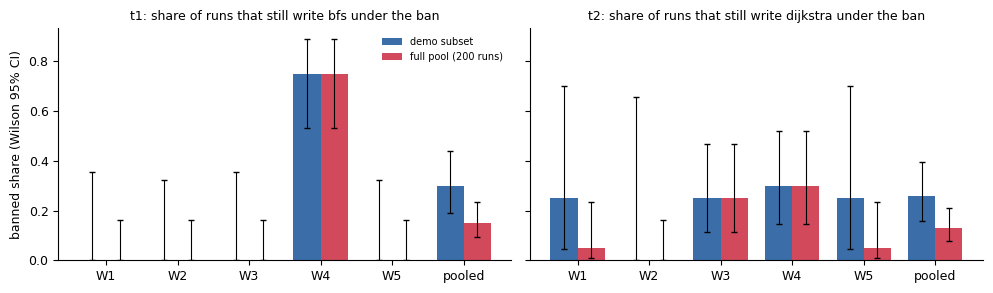

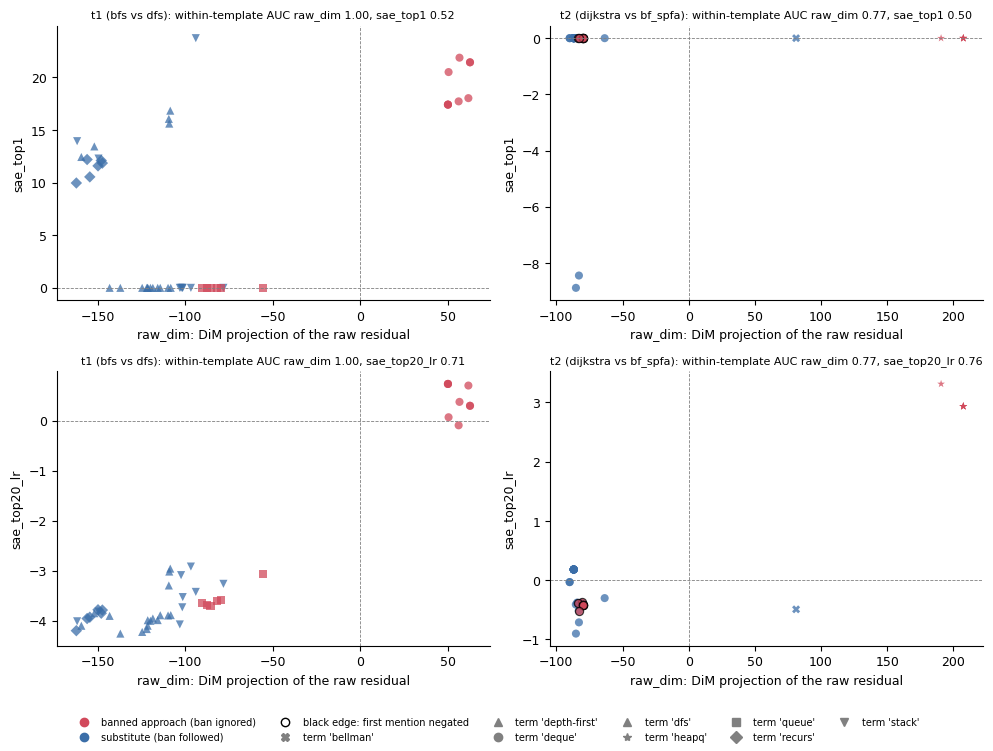

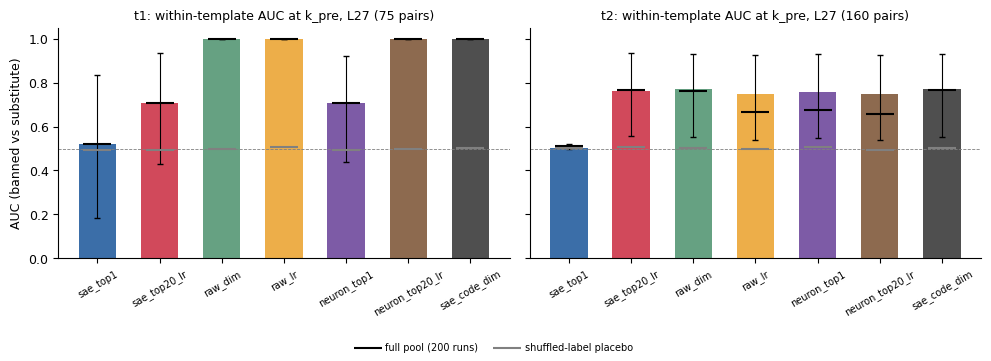

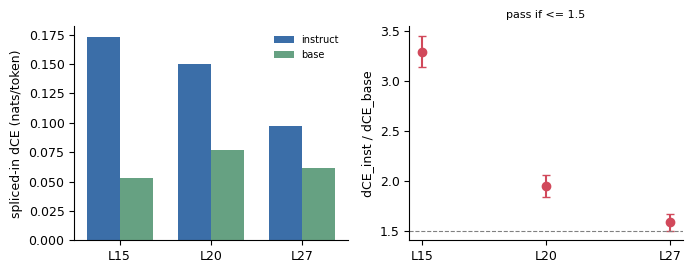

In [14]:
# (notebook) figures; palette and style from src/figures.py
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
C = ["#3b6ea8", "#d1495b", "#66a182", "#edae49", "#7d5ba6", "#8d6a4f", "#4f4f4f"]
# marker = lexicon term that located the commit token (the token predicted at k_pre)
TERM_MARK = {"deque": "o", "heapq": "*", "queue": "s", "dfs": "^", "depth-first": "^", "stack": "v", "recurs": "D",
             "bellman": "X"}
term_of = lambda r: (r["evidence_term"] or "").lower()  # noqa: E731

# 1) banned share per ban wording (Wilson 95% CI): demo subset vs full pool
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
ws = TEMPLATE_IDS + ["pooled"]
x = np.arange(len(ws))
for ax, t in zip(axes, TASKS):
    for j, (name, src) in enumerate((("demo subset", fresh), ("full pool (200 runs)", FULL["fresh_pool_summary"]))):
        v = np.array([src["per_task"][t][w]["banned_share"] for w in ws], dtype=float)
        ci = np.array([src["per_task"][t][w]["banned_share_wilson"] for w in ws], dtype=float)
        ax.bar(x + (j - 0.5) * 0.38, v, 0.38, color=C[j], label=name,
               yerr=[np.clip(v - ci[:, 0], 0, None), np.clip(ci[:, 1] - v, 0, None)], capsize=2, error_kw={"lw": 0.8})
    ax.set_xticks(x, ws)
    ax.set_title(f"{t}: share of runs that still write {BANNED[t]} under the ban", fontsize=9)
axes[0].set_ylabel("banned share (Wilson 95% CI)")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

# 2) per-run readout geometry at k_pre (L27): every run in the plane of two exp3-fitted readout axes
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for col, t in enumerate(TASKS):
    key = f"{t}|L{READOUT_LAYER}|{POS}"
    ii, S = rep["configs"][key]["run_index"], rep["configs"][key]["run_scores"]
    lab = np.array([C1_ROWS[i]["label"] for i in ii])
    term = np.array([term_of(C1_ROWS[i]) for i in ii])
    neg = np.array([bool(C1_ROWS[i]["negated_first_mention"]) for i in ii])
    for row, ym in enumerate(("sae_top1", "sae_top20_lr")):
        ax = axes[row, col]
        xs, ys = np.array(S["raw_dim"]), np.array(S[ym])
        for cl, c in ((SUBSTITUTE[t], C[0]), (BANNED[t], C[1])):
            for tm in sorted(set(term)):
                for ng in (False, True):
                    m = (lab == cl) & (term == tm) & (neg == ng)
                    if m.any():
                        ax.scatter(xs[m], ys[m], s=34, marker=TERM_MARK.get(tm, "."), color=c, alpha=0.75,
                                   edgecolors="black" if ng else "none", linewidths=0.9)
        ax.axvline(0, color="grey", lw=0.6, ls="--")
        ax.axhline(0, color="grey", lw=0.6, ls="--")
        ax.set_xlabel("raw_dim: DiM projection of the raw residual")
        ax.set_ylabel(ym)
        r = rep["configs"][key]["transfer_from_exp3"]
        ax.set_title(f"{t} ({BANNED[t]} vs {SUBSTITUTE[t]}): within-template AUC raw_dim "
                     f"{r['raw_dim']['auc_within_template']:.2f}, {ym} {r[ym]['auc_within_template']:.2f}", fontsize=8)
seen = sorted({term_of(r) for r in C1_ROWS if r["scores"]})
handles = [plt.Line2D([], [], ls="", marker="o", color=C[1], label="banned approach (ban ignored)"),
           plt.Line2D([], [], ls="", marker="o", color=C[0], label="substitute (ban followed)"),
           plt.Line2D([], [], ls="", marker="o", color="white", markeredgecolor="black",
                      label="black edge: first mention negated")] + \
          [plt.Line2D([], [], ls="", marker=TERM_MARK.get(tm, "."), color="grey", label=f"term '{tm}'") for tm in seen]
fig.legend(handles=handles, ncol=6, frameon=False, fontsize=7, loc="lower center")
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

# 3) within-template AUC per readout (adapted from the replication panel of fig_latent_vs_dim in src/figures.py)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
x = np.arange(len(METHODS))
for ax, t in zip(axes, TASKS):
    key = f"{t}|L{READOUT_LAYER}|{POS}"
    r = rep["configs"][key]["transfer_from_exp3"]
    v = np.array([r[m]["auc_within_template"] for m in METHODS], dtype=float)
    ci = np.array([[np.nan if c is None else c for c in r[m]["within_ci_runs"]] for m in METHODS], dtype=float)
    ax.bar(x, v, 0.6, color=[C[j % len(C)] for j in range(len(METHODS))],
           yerr=[np.clip(v - ci[:, 0], 0, None), np.clip(ci[:, 1] - v, 0, None)], capsize=2, error_kw={"lw": 0.8})
    ax.scatter(x, [FULL_REP[key]["transfer_from_exp3"][m]["auc_within_template"] for m in METHODS],
               marker="_", s=400, color="black", label="full pool (200 runs)", zorder=3)
    ax.scatter(x, [ver["checks"][f"placebo_replication_shuffled_{m}_{key}"]["placebo_mean_auc"] for m in METHODS],
               marker="_", s=400, color="grey", label="shuffled-label placebo", zorder=3)
    ax.axhline(0.5, color="grey", lw=0.6, ls="--")
    ax.set_xticks(x, METHODS, rotation=30, fontsize=7)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{t}: within-template AUC at {POS}, L{READOUT_LAYER} "
                 f"({r['raw_dim']['n_within_pairs']} pairs)", fontsize=9)
axes[0].set_ylabel("AUC (banned vs substitute)")
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, fontsize=7, ncol=2, loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

# 4) SAE base->instruct transfer test of the full run (fig_transfer of src/figures.py; input: the demo data)
T = FULL["transfer_test"]
Ls = sorted(T["layers"], key=int)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
x = np.arange(len(Ls))
axes[0].bar(x - 0.18, [T["layers"][L]["dce_inst"] for L in Ls], 0.36, color=C[0], label="instruct")
axes[0].bar(x + 0.18, [T["layers"][L]["dce_base"] for L in Ls], 0.36, color=C[2], label="base")
axes[0].set_xticks(x, [f"L{L}" for L in Ls])
axes[0].set_ylabel("spliced-in dCE (nats/token)")
axes[0].legend(frameon=False, fontsize=7)
r = [T["layers"][L]["ratio"] for L in Ls]
ci = [T["layers"][L]["ratio_ci95"] or [np.nan, np.nan] for L in Ls]
axes[1].errorbar(x, r, yerr=[[a - c[0] for a, c in zip(r, ci)], [c[1] - a for a, c in zip(r, ci)]], fmt="o",
                 color=C[1], capsize=3)
axes[1].axhline(1.5, color="grey", ls="--", lw=0.8)
axes[1].set_xticks(x, [f"L{L}" for L in Ls])
axes[1].set_ylabel("dCE_inst / dCE_base")
axes[1].set_title("pass if <= 1.5", fontsize=8)
fig.tight_layout()  # original: _save(fig, "fig_transfer")
plt.show()

## Scaling back to the full run

- **Parameters.** This notebook already uses the original `N_BOOT = 2000` and `N_PLACEBO = 200`.
- **The 200-run pool.** The 100-run subset is the only reduction. The parent experiment folder's `full_method_out.json` holds all 200 runs in its `fresh_ban_pool_protocol_v2` dataset, with the same fields except the two this demo adds:
  - `metadata_sample_id` is `(metadata_seed - 20261020) % 20`;
  - `metadata_generated_code` is in `results/labelled_c1.jsonl`.

  `build_mini_demo_data.py` shows how the subset was drawn.
- **The complete pipeline.** It runs from the experiment folder with `method.py`. It needs a 16 GB GPU and about 1 GPU-hour, plus the Qwen3-8B / Qwen3-8B-FP8 / Qwen3-8B-Base checkpoints, the Qwen-Scope SAE (`Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50`) and the iteration-1 exp3 states:

```bash
uv venv --python 3.12 .venv && uv pip install --python .venv/bin/python -r pyproject.toml
uv run method.py --stage B            # CPU: layer probe, SAE alignment, readout (i) discovery on exp3 states
uv run method.py --stage vllm1        # GPU: C1 fresh pool + E5 same-seed CRN (C1_PER_TEMPLATE=20, CRN_SEEDS_N=30)
uv run method.py --stage vllm2 --part traces --n 5
uv run method.py --stage label
uv run method.py --stage hf           # GPU: E2 states + attention, E1 SAE transfer test, E4 J-lens
uv run method.py --stage vllm2 --part resample --n 4
uv run method.py --stage vllm2 --part complete --n 1
uv run method.py --stage label && uv run method.py --stage analyse
uv run method.py --stage final && uv run method.py --stage figures && uv run method.py --stage verify
```

Beyond this demo, the full run covers:
- layers L15 and L20 and the k16 position;
- the nested re-selection of latents inside the fresh pool;
- the attention (ii) and prime-veto (iii) readouts;
- thought anchors, the same-seed CRN test and the J-lens gate.

**Caveats.**
- Every readout here is descriptive, not causal.
- The SAE was trained on the base model and fails the base-to-instruct transfer test, so the latent readouts work on out-of-distribution activations.
- The T1 within-template result rests on a single wording (W4, 75 pairs).
- For both classes, the commit token is often the ` deque` import, so "k_pre" means *the state at the first lexicon match*, not *the state at the algorithm decision*.